# Client Profitability & Growth Diagnostic
**Question:** Where is the client leaving money on the table versus peers, which levers are worth pulling, and what is that worth in valuation terms?

**Hypotheses to test (edit after you see the data)**
1. The client's margin gap vs peers is driven by cost of goods, not overheads.
2. Working-capital efficiency (cash conversion cycle) lags the best peer.
3. Modest, realistic improvements in 2-3 levers move enterprise value more than an extra point of revenue growth.

**Flow:** Data → Profitability (DuPont) → Peer benchmarking → Scenario model & DCF → Lever sizing → Recommendations & roadmap

In [3]:
import warnings; warnings.filterwarnings("ignore")
import yfinance as yf, pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

# ---- CONFIG: change these to switch client / peers -------------------------
CLIENT = "ASIANPAINT.NS"
PEERS  = ["BERGEPAINT.NS", "KANSAINER.NS", "INDIGOPNTS.NS"]
CR = 1e7   # INR -> crore
TAX, WACC, TERMINAL_G, CAPEX_TO_EBITDA = 0.25, 0.11, 0.05, 0.25
# -----------------------------------------------------------------------------
ALL = [CLIENT] + PEERS

## 1. Data pull and clean

In [4]:
def line(df, names):
    for n in names:
        if n in df.index:
            return df.loc[n]
    return pd.Series(dtype=float)

def build_metrics(tkr):
    t = yf.Ticker(tkr)
    inc, bs = t.financials, t.balance_sheet
    d = pd.DataFrame({
        "Revenue": line(inc, ["Total Revenue", "Operating Revenue"]),
        "COGS":    line(inc, ["Cost Of Revenue"]),
        "EBITDA":  line(inc, ["EBITDA", "Normalized EBITDA"]),
        "NetIncome": line(inc, ["Net Income", "Net Income Common Stockholders"]),
        "Assets":  line(bs, ["Total Assets"]),
        "Equity":  line(bs, ["Stockholders Equity", "Common Stock Equity"]),
        "Rec":     line(bs, ["Accounts Receivable", "Receivables"]),
        "Inv":     line(bs, ["Inventory"]),
        "Pay":     line(bs, ["Accounts Payable", "Payables"]),
    }).sort_index()
    d.index = pd.to_datetime(d.index).year
    d["Rev growth"]        = d.Revenue.pct_change()
    d["Gross margin"]      = 1 - d.COGS / d.Revenue
    d["EBITDA margin"]     = d.EBITDA / d.Revenue
    d["Net margin"]        = d.NetIncome / d.Revenue
    d["Asset turnover"]    = d.Revenue / d.Assets
    d["Equity multiplier"] = d.Assets / d.Equity
    d["ROE"]               = d.NetIncome / d.Equity
    d["DSO"] = d.Rec / d.Revenue * 365
    d["DIO"] = d.Inv / d.COGS * 365
    d["DPO"] = d.Pay / d.COGS * 365
    d["CCC"] = d.DSO + d.DIO - d.DPO
    return d

data = {tk: build_metrics(tk) for tk in ALL}
data[CLIENT].tail()

,Revenue,COGS,EBITDA,NetIncome,Assets,Equity,Rec,Inv,Pay,Rev growth,Gross margin,EBITDA margin,Net margin,Asset turnover,Equity multiplier,ROE,DSO,DIO,DPO,CCC
2022,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2023,"343,887,100,000.00","212,462,900,000.00","66,913,000,000.00","41,064,500,000.00","257,980,000,000.00","159,922,300,000.00","46,377,400,000.00","62,106,400,000.00","36,673,200,000.00",NaN,0.38,0.19,0.12,1.33,1.61,0.26,49.22,106.70,63.00,92.92
2024,"353,954,200,000.00","201,743,000,000.00","84,059,400,000.00","54,602,300,000.00","299,240,900,000.00","187,283,000,000.00","48,892,300,000.00","59,234,100,000.00","39,169,200,000.00",0.03,0.43,0.24,0.15,1.18,1.60,0.29,50.42,107.17,70.87,86.72
2025,"338,151,700,000.00","195,923,600,000.00","63,564,300,000.00","36,672,300,000.00","303,713,700,000.00","193,998,100,000.00","43,142,400,000.00","67,192,700,000.00","38,919,200,000.00",-0.04,0.42,0.19,0.11,1.11,1.57,0.19,46.57,125.18,72.51,99.24
2026,"355,409,000,000.00","201,194,900,000.00","74,277,000,000.00","43,253,500,000.00","345,344,900,000.00","213,715,900,000.00","44,623,300,000.00","57,436,900,000.00","39,189,800,000.00",0.05,0.43,0.21,0.12,1.03,1.62,0.20,45.83,104.20,71.10,78.93


## 2. Client profitability: trend and DuPont

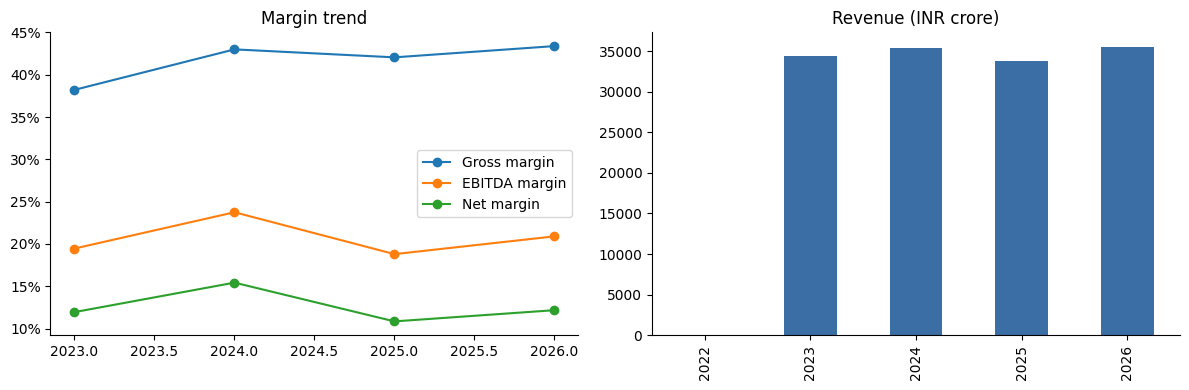

,Net margin,Asset turnover,Equity multiplier,ROE
2023,0.12,1.33,1.61,0.26
2024,0.15,1.18,1.60,0.29
2025,0.11,1.11,1.57,0.19
2026,0.12,1.03,1.62,0.20


In [5]:
c = data[CLIENT]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
c[["Gross margin", "EBITDA margin", "Net margin"]].dropna(how="all").plot(ax=ax[0], marker="o", title="Margin trend")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
(c["Revenue"] / CR).plot.bar(ax=ax[1], title="Revenue (INR crore)", color="#3b6ea5")
plt.tight_layout(); plt.show()

# ROE = Net margin x Asset turnover x Equity multiplier
c[["Net margin", "Asset turnover", "Equity multiplier", "ROE"]].dropna(how="all")

## 3. Peer benchmarking

In [6]:
def valuation(tkr):
    try:
        i = yf.Ticker(tkr).info
        return {"Mkt cap (cr)": (i.get("marketCap") or np.nan) / CR,
                "EV (cr)": (i.get("enterpriseValue") or np.nan) / CR,
                "EV/EBITDA": i.get("enterpriseToEbitda", np.nan),
                "P/E": i.get("trailingPE", np.nan)}
    except Exception:
        return {"Mkt cap (cr)": np.nan, "EV (cr)": np.nan, "EV/EBITDA": np.nan, "P/E": np.nan}

cols = ["Rev growth", "Gross margin", "EBITDA margin", "Net margin", "ROE", "Asset turnover", "CCC"]
bench = pd.DataFrame({tk: data[tk][cols].dropna(how="all").iloc[-1] for tk in ALL}).T
bench = bench.join(pd.DataFrame({tk: valuation(tk) for tk in ALL}).T)
bench.loc["Peer median"] = bench.loc[PEERS].median()
bench

,Rev growth,Gross margin,EBITDA margin,Net margin,ROE,Asset turnover,CCC,Mkt cap (cr),EV (cr),EV/EBITDA,P/E
ASIANPAINT.NS,0.05,0.43,0.21,0.12,0.20,1.03,78.93,"231,512.60","227,616.94",33.05,48.68
BERGEPAINT.NS,0.03,0.40,0.16,0.10,0.16,1.17,82.07,"52,260.25","51,629.18",28.32,43.01
KANSAINER.NS,0.03,0.35,0.13,0.07,0.09,0.92,88.80,"14,666.96","12,356.40",13.20,24.44
INDIGOPNTS.NS,0.05,0.46,0.19,0.10,0.13,0.86,55.31,"5,149.87","4,831.13",17.63,32.08
Peer median,0.03,0.40,0.16,0.10,0.13,0.92,82.07,"14,666.96","12,356.40",17.63,32.08


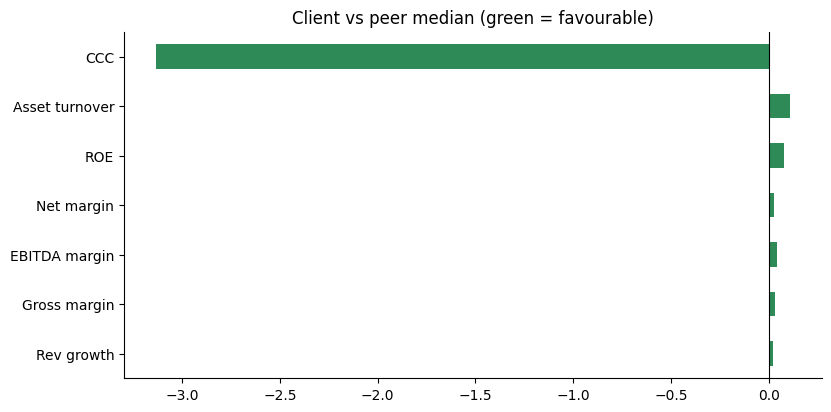

,Client minus peer median
Rev growth,0.02
Gross margin,0.03
EBITDA margin,0.04
Net margin,0.03
ROE,0.08
Asset turnover,0.11
CCC,-3.13


In [7]:
# Gap vs peer median: where is the client ahead or behind?
gap = (bench.loc[CLIENT, cols] - bench.loc["Peer median", cols]).rename("Client minus peer median")
higher_is_worse = {"CCC"}
colors = ["#c0392b" if (v > 0) == (k in higher_is_worse) and v != 0 else "#2e8b57" for k, v in gap.items()]
gap.plot.barh(color=colors, title="Client vs peer median (green = favourable)")
plt.axvline(0, color="k", lw=0.8); plt.show()
gap.to_frame()

## 4. Scenario model and DCF
Five-year forecast built off the client's latest actuals. Scenarios are **assumptions you should defend**, so anchor them to the history and peer benchmarks above.

In [8]:
base = c.dropna(subset=["Revenue", "EBITDA"]).iloc[-1]
hist_g = c["Revenue"].pct_change().dropna().mean()
print(f"Historical avg revenue growth: {hist_g:.1%} | Latest EBITDA margin: {base['EBITDA margin']:.1%}")

scenarios = {   # (revenue growth p.a., EBITDA margin in year 5)
    "Bear": (hist_g * 0.6, base["EBITDA margin"] - 0.02),
    "Base": (hist_g,       base["EBITDA margin"]),
    "Bull": (hist_g * 1.3, base["EBITDA margin"] + 0.02),
}

def dcf(g, m_end, years=5):
    rev = base["Revenue"] * (1 + g) ** np.arange(1, years + 1)
    margin = np.linspace(base["EBITDA margin"], m_end, years)
    ebitda = rev * margin
    fcf = ebitda * (1 - TAX) - ebitda * CAPEX_TO_EBITDA
    disc = (1 + WACC) ** np.arange(1, years + 1)
    tv = fcf[-1] * (1 + TERMINAL_G) / (WACC - TERMINAL_G)
    ev = (fcf / disc).sum() + tv / disc[-1]
    return pd.DataFrame({"Revenue": rev, "EBITDA": ebitda, "FCF": fcf}, index=range(1, years + 1)), ev

results, ev_by_case = {}, {}
for name, (g, m) in scenarios.items():
    results[name], ev_by_case[name] = dcf(g, m)

mkt_ev = bench.loc[CLIENT, "EV (cr)"]
ev_table = pd.Series(ev_by_case).div(CR).rename("DCF EV (cr)").to_frame()
ev_table["Market EV (cr)"] = mkt_ev
ev_table["DCF vs market"] = ev_table["DCF EV (cr)"] / mkt_ev - 1
ev_table

Historical avg revenue growth: 1.2% | Latest EBITDA margin: 20.9%


,DCF EV (cr),Market EV (cr),DCF vs market
Bear,"49,537.24","227,616.94",-0.78
Base,"55,105.94","227,616.94",-0.76
Bull,"60,583.58","227,616.94",-0.73


In [9]:
# WACC x terminal growth sensitivity (base case)
g0, m0 = scenarios["Base"]
waccs, tgs = [0.09, 0.10, 0.11, 0.12, 0.13], [0.03, 0.04, 0.05, 0.06]
grid = pd.DataFrame(index=[f"{w:.0%}" for w in waccs], columns=[f"{t:.0%}" for t in tgs], dtype=float)
_w, _t = WACC, TERMINAL_G
for w in waccs:
    for t in tgs:
        WACC, TERMINAL_G = w, t
        grid.loc[f"{w:.0%}", f"{t:.0%}"] = dcf(g0, m0)[1] / CR
WACC, TERMINAL_G = _w, _t
grid.index.name, grid.columns.name = "WACC", "Terminal g"
grid.style.format("{:,.0f}").background_gradient(cmap="Blues")

Terminal g,3%,4%,5%,6%
WACC,,,,
9%,"58,897","68,201","82,156","105,416"
10%,"50,552","56,960","65,930","79,385"
11%,"44,292","48,927","55,106","63,757"
12%,"39,421","42,899","47,370","53,331"
13%,"35,523","38,208","41,564","45,879"


## 5. Lever sizing: cost saving and revenue enhancement
Each lever is sized on latest-year actuals, then converted to EBITDA and enterprise value using the **peer-median EV/EBITDA**. Working-capital levers release cash rather than lift EBITDA, so they are shown separately.

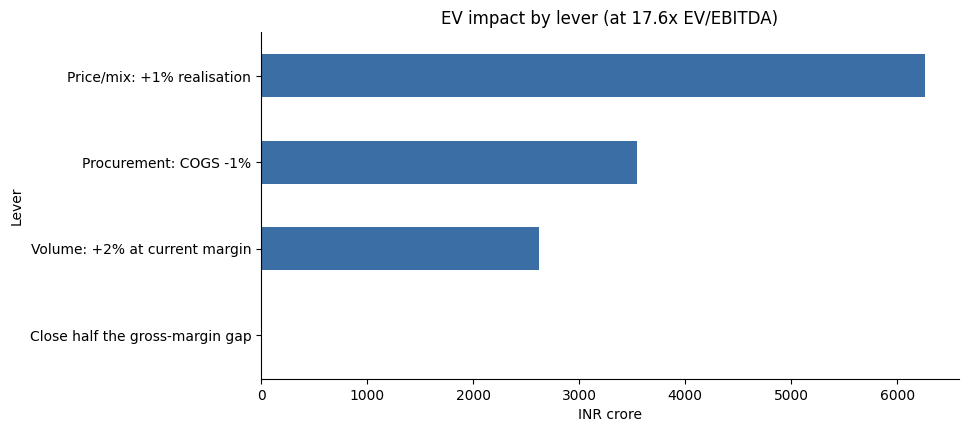

,EBITDA uplift (cr),EV impact (cr)
Lever,,
Close half the gross-margin gap,0.00,0.00
Volume: +2% at current margin,148.55,"2,618.56"
Procurement: COGS -1%,201.19,"3,546.46"
Price/mix: +1% realisation,355.41,"6,264.79"


,Cash released (cr)
Inventory days -10,551.22
Receivable days -10,973.72
Payable days +5,275.61


In [10]:
rev, cogs = base["Revenue"], base["COGS"]
mult = bench.loc["Peer median", "EV/EBITDA"]
if pd.isna(mult): mult = bench.loc[CLIENT, "EV/EBITDA"]

levers = pd.DataFrame([
    ("Procurement: COGS -1%",          cogs * 0.01),
    ("Price/mix: +1% realisation",     rev * 0.01),
    ("Volume: +2% at current margin",  rev * 0.02 * base["EBITDA margin"]),
    ("Close half the gross-margin gap", max(0, -gap["Gross margin"]) * 0.5 * rev),
], columns=["Lever", "EBITDA uplift (INR)"]).set_index("Lever")
levers["EBITDA uplift (cr)"] = levers["EBITDA uplift (INR)"] / CR
levers["EV impact (cr)"] = levers["EBITDA uplift (cr)"] * mult
levers = levers.drop(columns="EBITDA uplift (INR)").sort_values("EV impact (cr)")

levers["EV impact (cr)"].plot.barh(color="#3b6ea5", title=f"EV impact by lever (at {mult:.1f}x EV/EBITDA)")
plt.xlabel("INR crore"); plt.show()

wc = pd.DataFrame({
    "Cash released (cr)": [
        10 * cogs / 365 / CR,                        # DIO -10 days
        10 * rev / 365 / CR,                         # DSO -10 days
        5 * cogs / 365 / CR,                         # DPO +5 days
    ]}, index=["Inventory days -10", "Receivable days -10", "Payable days +5"])
display(levers); display(wc)

## 6. Recommendations and roadmap


| Horizon | Initiative | Lever | Est. EBITDA / cash impact | Owner / KPI |
|---|---|---|---|---|
| 0-3 months | _Quick wins: procurement renegotiation, discount leakage review_ | COGS, price | | |
| 3-9 months | _Working-capital programme_ | DIO / DSO / DPO | | |
| 9-18 months | _Mix shift / premiumisation, network optimisation_ | Price/mix, volume | | |

**Risks and assumptions:** _WACC and terminal growth choice, data limits (yfinance is standardised, not audited), peer comparability._